#**Gaussian Naive Bayes classifier**

# **1. Importing Libraries**

**First we will be importing the required libraries:**

1. pandas: for data manipulation
2. load_iris: to load dataset
2. train_test_split: to split the data into training and testing sets
4. GaussianNB: for the Gaussian Naive Bayes classifier
5. accuracy_score: to evaluate the model
6. LabelEncoder: to encode the categorical target variable.

In [2]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

# **2. Loading the Dataset and Preparing Features and Target Variable**

After that we will load the Iris dataset from a CSV file named "Iris.csv" into a pandas DataFrame. Then we will separate the features (X) and the target variable (y) from the dataset. Features are obtained by dropping the "Species" column and the target variable is set to the "Species" column which we will be predicting.

In [3]:
iris = load_iris()

data = pd.DataFrame(iris.data, columns=iris.feature_names)
data['Species'] = iris.target

X = data.drop("Species", axis=1)
y = data['Species']

# **3. Encoding and Splitting the Dataset**
* Since the target variable "Species" is categorical we will be using Label Encoder to convert it into numerical form. This is necessary for the Gaussian Naive Bayes classifier as it requires numerical inputs.
* We will be splitting the dataset into training and testing sets using the train_test_split function. 70% of the data is used for training and 30% is used for testing. The random_state parameter ensures reproducibility of the same data.

In [4]:
le = LabelEncoder()
y = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# **4. Creating and Training the Model**
We will be creating a Gaussian Naive Bayes Classifier (gnb) and then training it on the training data using the fit method.

In [5]:
gnb = GaussianNB()

gnb.fit(X_train, y_train)

GaussianNB()

# **5. Plotting 1D Gaussian Distributions for All Features**
We visualize the Gaussian distributions for each feature in the Iris dataset across all classes. The distributions are modeled by the Gaussian Naive Bayes classifier where each class is represented by a normal (Gaussian) distribution with a mean and variance specific to each feature. Separate plots are created for each feature in the dataset showing how each class's feature values are distributed.

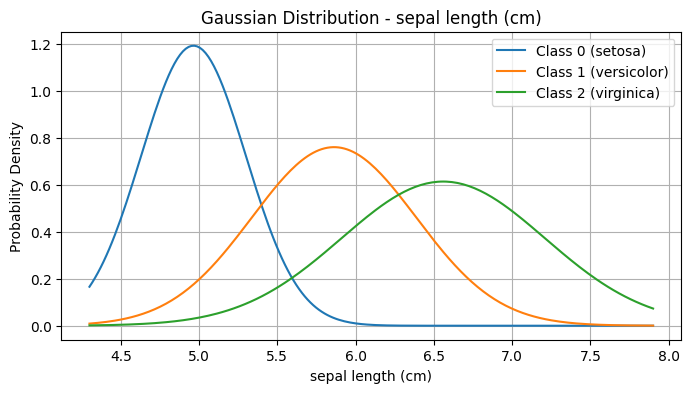

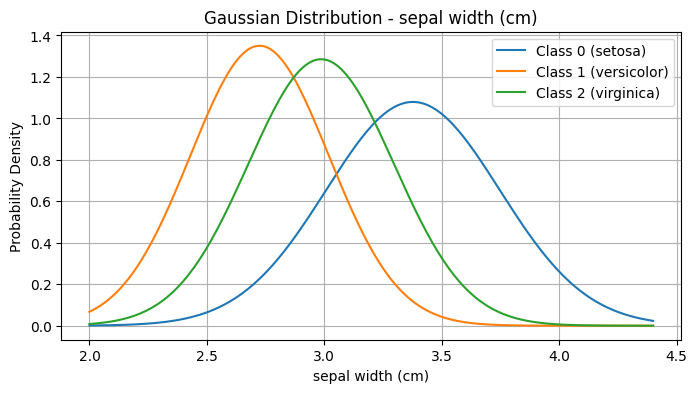

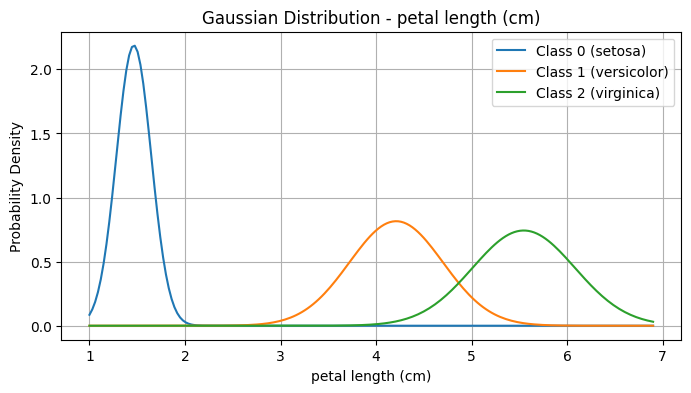

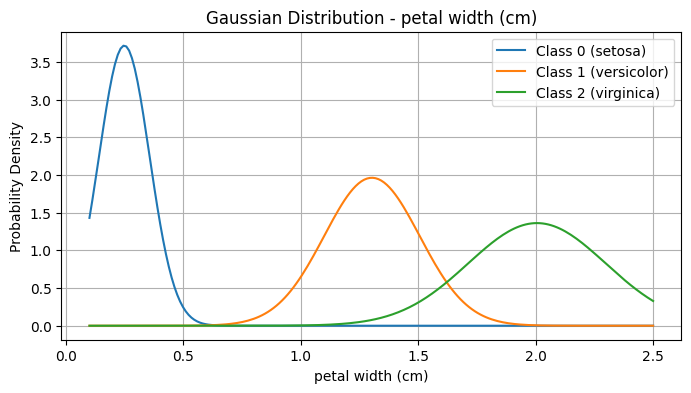

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

feature_names = iris.feature_names
num_features = len(feature_names)
num_classes = len(np.unique(y))

X_np = X.to_numpy()

for feature_index in range(num_features):
    feature_name = feature_names[feature_index]
    x_vals = np.linspace(X_np[:, feature_index].min(), X_np[:, feature_index].max(), 200)

    plt.figure(figsize=(8, 4))

    for cls in range(num_classes):
        mean = gnb.theta_[cls, feature_index]
        std = np.sqrt(gnb.var_[cls, feature_index])
        y_vals = norm.pdf(x_vals, mean, std)
        plt.plot(x_vals, y_vals, label=f"Class {cls} ({iris.target_names[cls]})")

    plt.title(f"Gaussian Distribution - {feature_name}")
    plt.xlabel(feature_name)
    plt.ylabel("Probability Density")
    plt.legend()
    plt.grid(True)

    plt.show()

# **6. Making Predictions**
At last we will be using the trained model to make predictions on the testing data.

In [7]:
y_pred = gnb.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"The Accuracy of Prediction on Iris Flower is: {accuracy}")

The Accuracy of Prediction on Iris Flower is: 0.9777777777777777


#**MultinomialNB**

# **1. Importing Libraries:**
First, we import the required libraries used for data processing, model training and evaluation.

* pandas: Used to handle data in DataFrame format.
* CountVectorizer: Converts text documents into a matrix of word counts.
* train_test_split: Splits the dataset into training and testing sets.
* MultinomialNB: A Naive Bayes classifier used for discrete features such as word counts.
* accuracy_score: Measures how accurately the model predicts the correct class.

In [8]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# **2. Creating the Dataset**
Next, we create a simple dataset containing text messages labelled as spam or not spam. This dataset is stored in a pandas DataFrame for easier processing.

In [9]:
data = {
    'text': [
        'Free money now',
        'Call now to claim your prize',
        'Meet me at the park',
        'Let’s catch up later',
        'Win a new car today!',
        'Lunch plans?',
        'Congratulations! You won a lottery',
        'Can you send me the report?',
        'Exclusive offer for you',
        'Are you coming to the meeting?'
    ],
    'label': ['spam', 'spam', 'not spam', 'not spam', 'spam', 'not spam', 'spam', 'not spam', 'spam', 'not spam']
}

df = pd.DataFrame(data)

# **3. Mapping Labels to Numerical Values**
Next, the labels spam and not spam are converted into numerical values. This step is required because machine learning models work with numerical data.

* spam: 1
* not spam: 0

In [10]:
df['label'] = df['label'].map({'spam': 1, 'not spam': 0})

# **4. Splitting the Data**
* X contains the text messages (features) and y contains the labels (target).
* The dataset is split into training (70%) and testing (30%) sets using train_test_split.

# **5. Vectorizing the Text Data**
Next, the text data is converted into numerical form using CountVectorizer. This method transforms text into vectors by counting the occurrences of each word.

* fit_transform(): Learns the vocabulary from the training data and converts it into a feature matrix.
* transform(): Converts the test data into the same feature space using the learned vocabulary.

In [11]:
X = df['text']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# **6. Training the Naive Bayes Model**
Next, a Multinomial Naive Bayes classifier is created and trained using the vectorized training data and the corresponding labels.

In [12]:
vectorizer = CountVectorizer()
X_train_vectors = vectorizer.fit_transform(X_train)
X_test_vectors = vectorizer.transform(X_test)

# **6. Training the Naive Bayes Model**
Next, a Multinomial Naive Bayes classifier is created and trained using the vectorized training data and the corresponding labels.

In [13]:
model = MultinomialNB()
model.fit(X_train_vectors, y_train)

MultinomialNB()

# **7. Making Predictions and Evaluating Accuracy**
After training the model, we use it to predict labels for the test data and then evaluate its performance using accuracy.

model.predict(): Generates predicted labels for the test dataset.
accuracy_score(): Compares predicted labels with the actual labels to measure model accuracy.

In [14]:
y_pred = model.predict(X_test_vectors)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%\n")

Accuracy: 66.67%



# **8. Predicting for a Custom Message**
Finally, we test the model with a custom message to see how it classifies new input data.

* vectorizer.transform(): Converts the custom message into a numerical vector using the learned vocabulary.
* model.predict(): Predicts whether the message is spam or not spam.
Interpret result: 1 represents Spam and 0 represents Not Spam.

In [15]:
custom_message = ["Congratulations, you've won a free vacation"]
print(custom_message)
custom_vector = vectorizer.transform(custom_message)
prediction = model.predict(custom_vector)
print("Prediction for custom message:", "Spam" if prediction[0] == 1 else "Not Spam")

["Congratulations, you've won a free vacation"]
Prediction for custom message: Spam


# **Bernoulli Naive Bayes**

# **1. Importing Libraries**
* In the code we have imported necessary libraries like pandas, numpy and sklearn. Bernoulli Naive Bayes is a part of sklearn package.

In [20]:
import numpy as np
import pandas as pd
from sklearn.naive_bayes import BernoulliNB
from sklearn.feature_extraction.text import CountVectorizer

# **2. Data Analysis**
In this code we have performed a quick data analysis that includes reading the data, dropping unnecessary columns, printing shape of data, information about dataset etc.

In [19]:
df=pd.read_csv("/content/spam_ham_dataset.csv")
print(df.shape)
print(df.columns)
df= df.drop(['Unnamed: 0'], axis=1)

(5171, 4)
Index(['Unnamed: 0', 'label', 'text', 'label_num'], dtype='object')
(5171, 4)
Index(['Unnamed: 0', 'label', 'text', 'label_num'], dtype='object')


# **3. Count Vectorizer**
In the code since text data is used to train our classifier we convert the text into a matrix comprising numbers using Count Vectorizer so that the model can perform well.

In [21]:
x = df["text"].values
y = df["label_num"].values

cv = CountVectorizer()

x = cv.fit_transform(x)

# **4. Data Splitting, Model Training and Prediction**

In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=0)\

bnb = BernoulliNB(binarize=0.0)
model = bnb.fit(X_train, y_train)
y_pred = bnb.predict(X_test)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.98      0.91       732
           1       0.92      0.56      0.70       303

    accuracy                           0.86      1035
   macro avg       0.88      0.77      0.80      1035
weighted avg       0.87      0.86      0.84      1035



In [23]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, classification_report

# 1. Load the dataset
df = pd.read_csv('spam_ham_dataset.csv')

# Feature column: 'text', Target column: 'label_num' (0 for ham, 1 for spam)
X = df['text']
y = df['label_num']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ---------------------------------------------------------
# 2. Vectorization suited for each Naive Bayes variant
# ---------------------------------------------------------

# A. Word Counts for Multinomial NB
count_vectorizer = CountVectorizer()
X_train_counts = count_vectorizer.fit_transform(X_train)
X_test_counts = count_vectorizer.transform(X_test)

# B. Binary Presence/Absence for Bernoulli NB
bern_vectorizer = CountVectorizer(binary=True)
X_train_bern = bern_vectorizer.fit_transform(X_train)
X_test_bern = bern_vectorizer.transform(X_test)

# C. Continuous TF-IDF Features for Gaussian NB
# Limiting features to prevent excessive memory usage during dense conversion (.toarray())
tfidf_vectorizer = TfidfVectorizer(max_features=3000)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train).toarray()
X_test_tfidf = tfidf_vectorizer.transform(X_test).toarray()

# ---------------------------------------------------------
# 3. Model Training & Evaluation
# ---------------------------------------------------------

# Multinomial Naive Bayes
mnb = MultinomialNB()
mnb.fit(X_train_counts, y_train)
mnb_preds = mnb.predict(X_test_counts)

# Bernoulli Naive Bayes
bnb = BernoulliNB()
bnb.fit(X_train_bern, y_train)
bnb_preds = bnb.predict(X_test_bern)

# Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train_tfidf, y_train)
gnb_preds = gnb.predict(X_test_tfidf)

# ---------------------------------------------------------
# 4. Results
# ---------------------------------------------------------

print("=== Model Performance Comparison ===")
print(f"Multinomial Naive Bayes Accuracy: {accuracy_score(y_test, mnb_preds):.4f}")
print(f"Bernoulli Naive Bayes Accuracy:   {accuracy_score(y_test, bnb_preds):.4f}")
print(f"Gaussian Naive Bayes Accuracy:    {accuracy_score(y_test, gnb_preds):.4f}")

print("\n=== Detailed Classification Report (Multinomial NB) ===")
print(classification_report(y_test, mnb_preds, target_names=['Ham (0)', 'Spam (1)']))

=== Model Performance Comparison ===
Multinomial Naive Bayes Accuracy: 0.9720
Bernoulli Naive Bayes Accuracy:   0.8454
Gaussian Naive Bayes Accuracy:    0.9681

=== Detailed Classification Report (Multinomial NB) ===
              precision    recall  f1-score   support

     Ham (0)       0.98      0.98      0.98       742
    Spam (1)       0.96      0.95      0.95       293

    accuracy                           0.97      1035
   macro avg       0.97      0.96      0.97      1035
weighted avg       0.97      0.97      0.97      1035



# **Ploting**

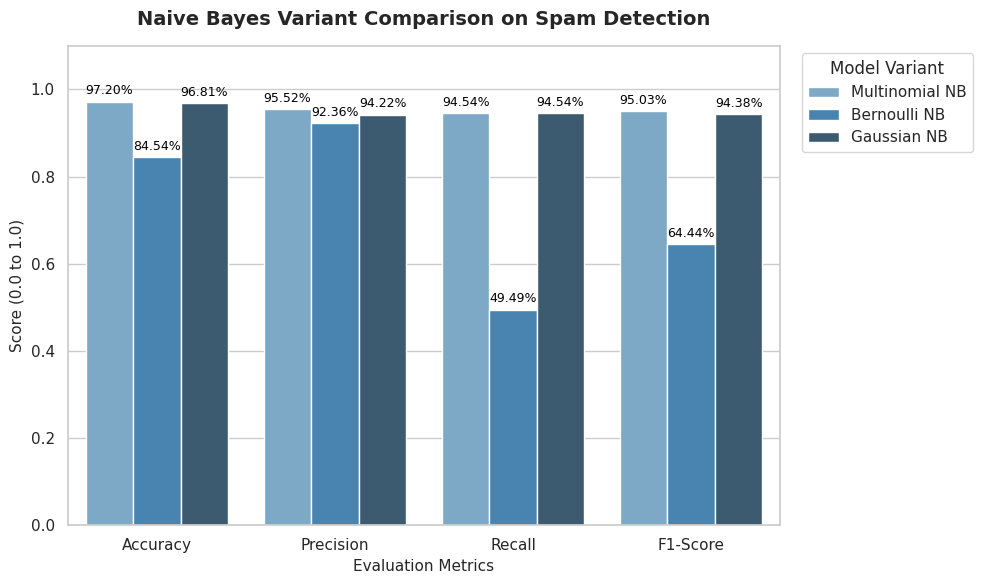

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Load Data
df = pd.read_csv('spam_ham_dataset.csv')

X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label_num'], test_size=0.2, random_state=42
)

# 2. Vectorization Strategies
count_vec = CountVectorizer()
X_tr_counts = count_vec.fit_transform(X_train)
X_te_counts = count_vec.transform(X_test)

bern_vec = CountVectorizer(binary=True)
X_tr_bern = bern_vec.fit_transform(X_train)
X_te_bern = bern_vec.transform(X_test)

tfidf_vec = TfidfVectorizer(max_features=3000)
X_tr_tfidf = tfidf_vec.fit_transform(X_train).toarray()
X_te_tfidf = tfidf_vec.transform(X_test).toarray()

# 3. Fit Models
models = {
    'Multinomial NB': MultinomialNB().fit(X_tr_counts, y_train).predict(X_te_counts),
    'Bernoulli NB': BernoulliNB().fit(X_tr_bern, y_train).predict(X_te_bern),
    'Gaussian NB': GaussianNB().fit(X_tr_tfidf, y_train).predict(X_te_tfidf)
}

# 4. Collect Evaluation Metrics
metrics_list = []
for name, preds in models.items():
    metrics_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds)
    })

metrics_df = pd.DataFrame(metrics_list)

# Reshape data for plotting
df_melted = pd.melt(metrics_df, id_vars=['Model'], var_name='Metric', value_name='Score')

# 5. Plot Comparison
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Bar plot
ax = sns.barplot(
    data=df_melted,
    x='Metric',
    y='Score',
    hue='Model',
    palette='Blues_d'
)

# Customize title and labels
plt.title('Naive Bayes Variant Comparison on Spam Detection', fontsize=14, fontweight='bold', pad=15)
plt.ylim(0, 1.1)
plt.ylabel('Score (0.0 to 1.0)', fontsize=11)
plt.xlabel('Evaluation Metrics', fontsize=11)
plt.legend(title='Model Variant', bbox_to_anchor=(1.02, 1), loc='upper left')

# Annotate exact score values on top of each bar
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.2%}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=9, color='black',
                    xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

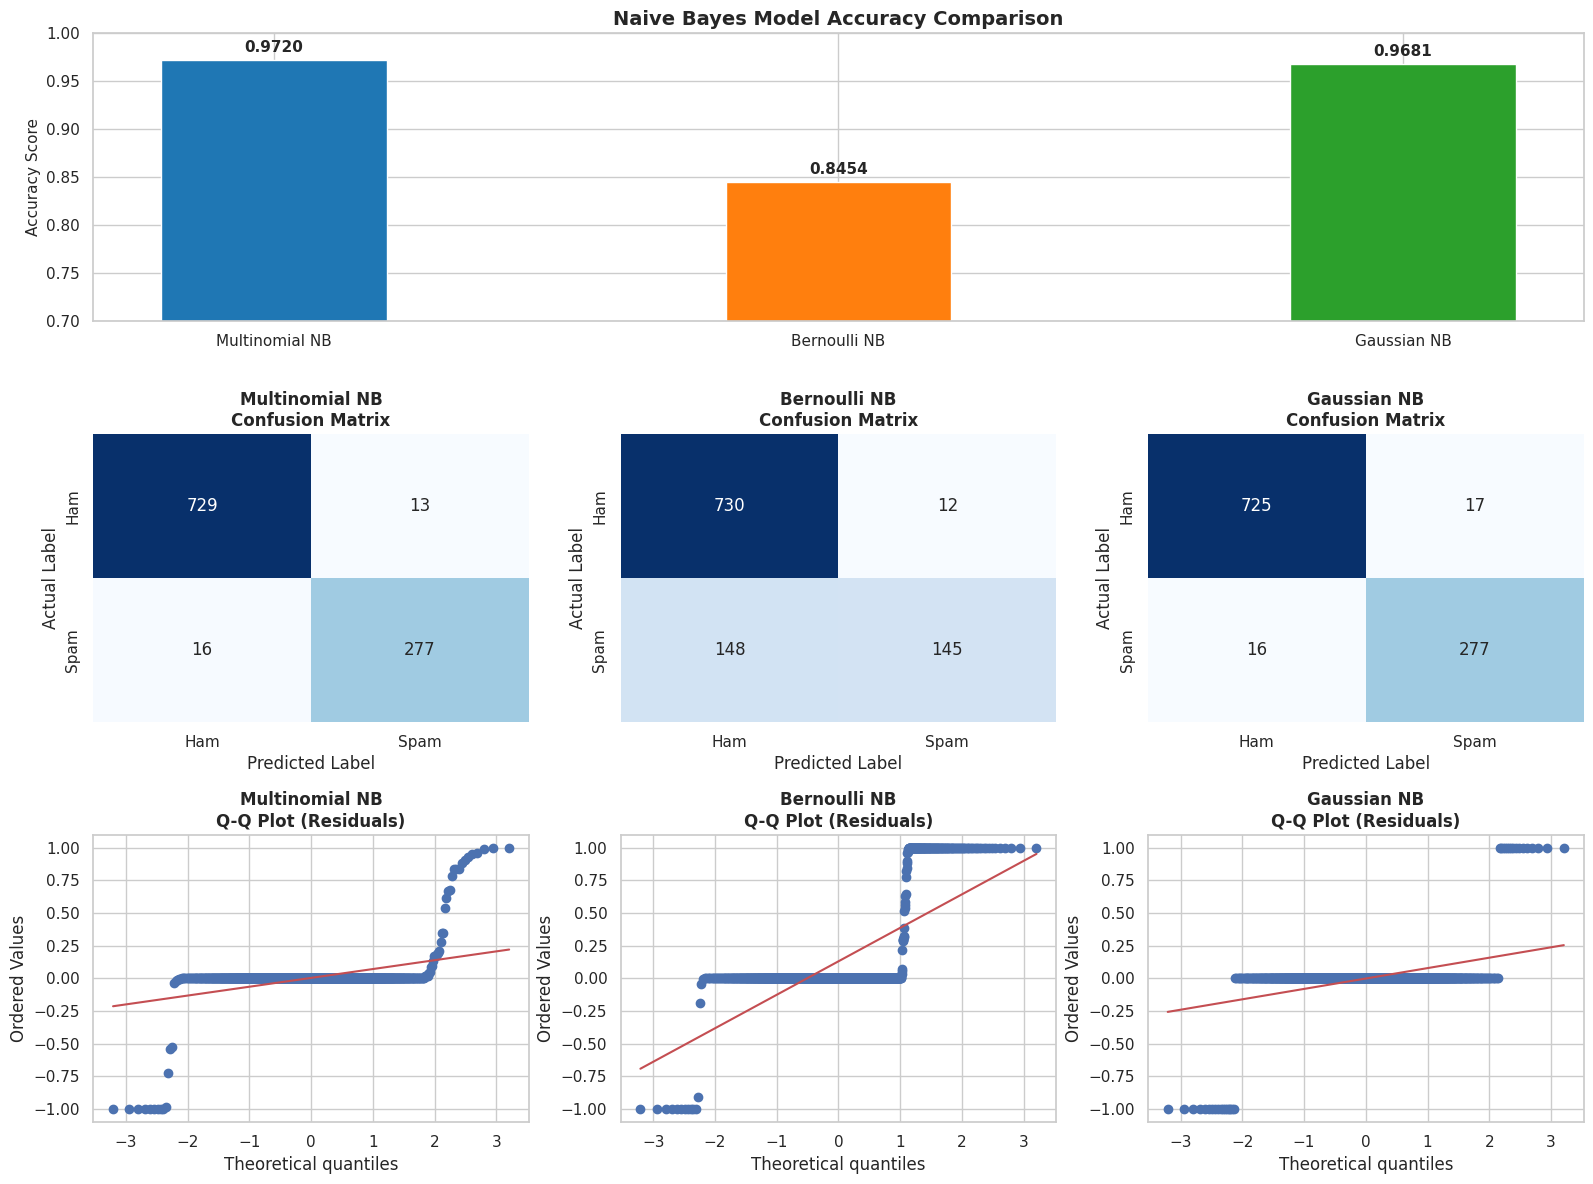

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Load data and split
df = pd.read_csv('spam_ham_dataset.csv')
X = df['text']
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Vectorization tailored to model assumptions
count_vec = CountVectorizer()
X_tr_counts = count_vec.fit_transform(X_train)
X_te_counts = count_vec.transform(X_test)

bern_vec = CountVectorizer(binary=True)
X_tr_bern = bern_vec.fit_transform(X_train)
X_te_bern = bern_vec.transform(X_test)

tfidf_vec = TfidfVectorizer(max_features=3000)
X_tr_tfidf = tfidf_vec.fit_transform(X_train).toarray()
X_te_tfidf = tfidf_vec.transform(X_test).toarray()

# 3. Fit models and compute evaluations
models = {
    'Multinomial NB': (MultinomialNB().fit(X_tr_counts, y_train), X_te_counts),
    'Bernoulli NB': (BernoulliNB().fit(X_tr_bern, y_train), X_te_bern),
    'Gaussian NB': (GaussianNB().fit(X_tr_tfidf, y_train), X_te_tfidf)
}

results = {}
for name, (model, X_te) in models.items():
    preds = model.predict(X_te)
    probs = model.predict_proba(X_te)[:, 1]
    acc = accuracy_score(y_test, preds)
    cm = confusion_matrix(y_test, preds)
    residuals = y_test - probs  # Difference between true binary class and predicted probability
    results[name] = {'acc': acc, 'cm': cm, 'residuals': residuals}

# 4. Visualization setup
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(16, 12))

# Row 1: Accuracy Bar Chart Comparison
ax_bar = plt.subplot(3, 3, (1, 3))
names = list(results.keys())
accuracies = [results[m]['acc'] for m in names]
bars = ax_bar.bar(names, accuracies, color=['#1f77b4', '#ff7f0e', '#2ca02c'], width=0.4)
ax_bar.set_ylim(0.7, 1.0)
ax_bar.set_ylabel("Accuracy Score", fontsize=11)
ax_bar.set_title("Naive Bayes Model Accuracy Comparison", fontsize=14, fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    ax_bar.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f"{yval:.4f}",
                ha='center', va='bottom', fontweight='bold', fontsize=11)

# Row 2: Confusion Matrices
for i, name in enumerate(names):
    ax_cm = plt.subplot(3, 3, 4 + i)
    cm = results[name]['cm']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax_cm,
                xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
    ax_cm.set_title(f"{name}\nConfusion Matrix", fontsize=12, fontweight='bold')
    ax_cm.set_xlabel("Predicted Label")
    ax_cm.set_ylabel("Actual Label")

# Row 3: Quantile-Quantile (Q-Q) Plots of Residuals
for i, name in enumerate(names):
    ax_qq = plt.subplot(3, 3, 7 + i)
    residuals = results[name]['residuals']
    stats.probplot(residuals, dist="norm", plot=ax_qq)
    ax_qq.set_title(f"{name}\nQ-Q Plot (Residuals)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()